# 01. EDA

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df_train = pd.read_csv("../train.csv")
df_train.shape

(1503424, 18)

In [4]:
df_train.head()

,item_id,user_id,region,city,parent_category_name,category_name,param_1,param_2,param_3,title,description,price,item_seq_number,activation_date,user_type,image,image_top_1,deal_probability
0,b912c3c6a6ad,e00f8ff2eaf9,Свердловская область,Екатеринбург,Личные вещи,Товары для детей и игрушки,Постельные принадлежности,NaN,NaN,Кокоби(кокон для сна),"Кокон для сна малыша,пользовались меньше месяц...",400.0,2,2017-03-28,Private,d10c7e016e03247a3bf2d13348fe959fe6f436c1caf64c...,1008.0,0.12789
1,2dac0150717d,39aeb48f0017,Самарская область,Самара,Для дома и дачи,Мебель и интерьер,Другое,NaN,NaN,Стойка для Одежды,"Стойка для одежды, под вешалки. С бутика.",3000.0,19,2017-03-26,Private,79c9392cc51a9c81c6eb91eceb8e552171db39d7142700...,692.0,0.00000
2,ba83aefab5dc,91e2f88dd6e3,Ростовская область,Ростов-на-Дону,Бытовая электроника,Аудио и видео,"Видео, DVD и Blu-ray плееры",NaN,NaN,Philips bluray,"В хорошем состоянии, домашний кинотеатр с blu ...",4000.0,9,2017-03-20,Private,b7f250ee3f39e1fedd77c141f273703f4a9be59db4b48a...,3032.0,0.43177
3,02996f1dd2ea,bf5cccea572d,Татарстан,Набережные Челны,Личные вещи,Товары для детей и игрушки,Автомобильные кресла,NaN,NaN,Автокресло,Продам кресло от0-25кг,2200.0,286,2017-03-25,Company,e6ef97e0725637ea84e3d203e82dadb43ed3cc0a1c8413...,796.0,0.80323
4,7c90be56d2ab,ef50846afc0b,Волгоградская область,Волгоград,Транспорт,Автомобили,С пробегом,ВАЗ (LADA),2110,"ВАЗ 2110, 2003",Все вопросы по телефону.,40000.0,3,2017-03-16,Private,54a687a3a0fc1d68aed99bdaaf551c5c70b761b16fd0a2...,2264.0,0.20797


### Пропуски

In [5]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1503424 entries, 0 to 1503423
Data columns (total 18 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   item_id               1503424 non-null  object 
 1   user_id               1503424 non-null  object 
 2   region                1503424 non-null  object 
 3   city                  1503424 non-null  object 
 4   parent_category_name  1503424 non-null  object 
 5   category_name         1503424 non-null  object 
 6   param_1               1441848 non-null  object 
 7   param_2               848882 non-null   object 
 8   param_3               640859 non-null   object 
 9   title                 1503424 non-null  object 
 10  description           1387148 non-null  object 
 11  price                 1418062 non-null  float64
 12  item_seq_number       1503424 non-null  int64  
 13  activation_date       1503424 non-null  object 
 14  user_type             1503424 non-

In [6]:
is_nan = df_train.isna().sum() / len(df_train) * 100
print("NaN values in train Dataset")
print(is_nan[is_nan > 0].sort_values(ascending=False))

NaN values in train Dataset
param_3        57.373369
param_2        43.536753
description     7.734079
image           7.488772
image_top_1     7.488772
price           5.677839
param_1         4.095718
dtype: float64


param_2 и param_3 заполнены лишь наполовину. Скорее всего, в дальнейшем их не буду использовать

### Количество уникальных значений у признаков

/var/folders/n2/f0z_cgls5bdf57pdyq0mwmch0000gn/T/ipykernel_1331/485157224.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45);


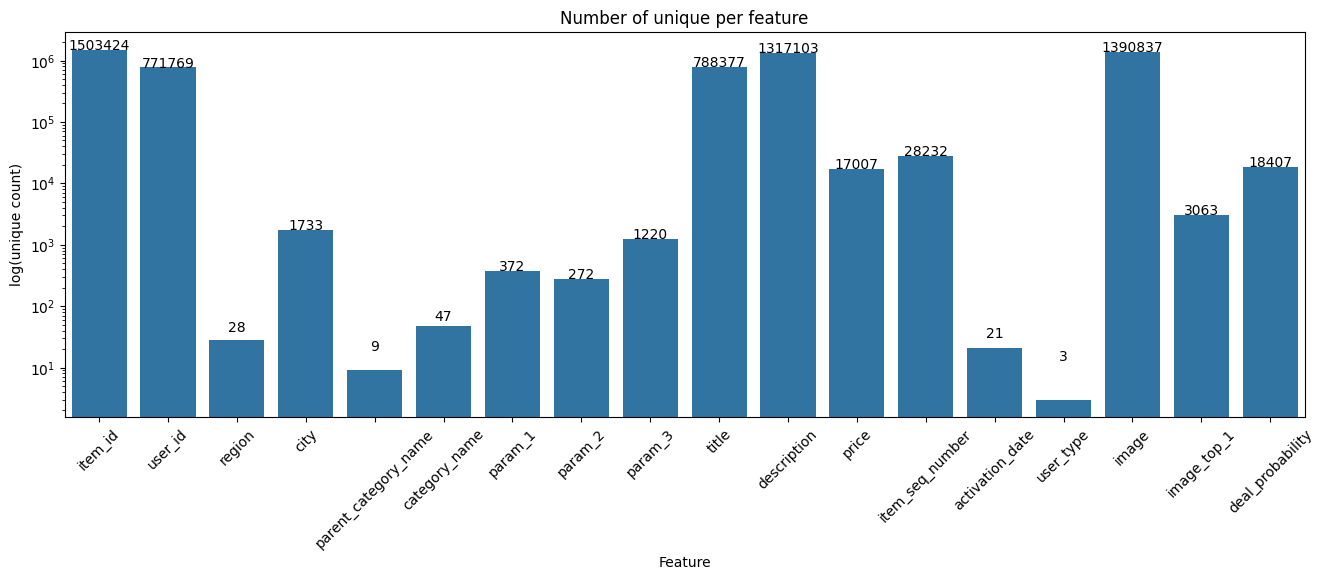

In [7]:
plt.figure(figsize=(16, 5))

cols = df_train.columns
uniques = [len(df_train[col].unique()) for col in cols]

ax = sns.barplot(x=cols, y=uniques, log=True)
ax.set(xlabel='Feature', ylabel='log(unique count)', title='Number of unique per feature')


for p, uniq in zip(ax.patches, uniques):
    ax.text(p.get_x() + p.get_width()/2.,
            uniq + 10,
            uniq,
            ha="center") 

ax.set_xticklabels(ax.get_xticklabels(), rotation=45);

### Распределение целевого признака

по количеству:

<Axes: >

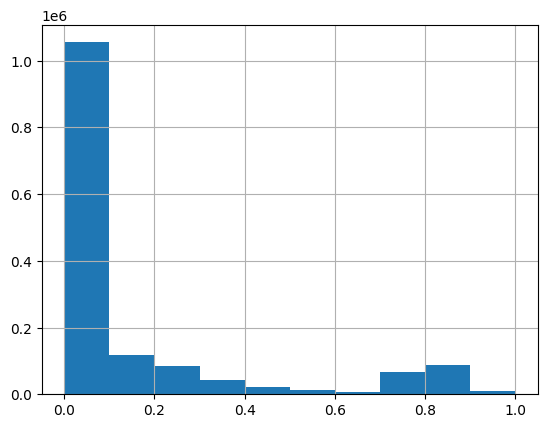

In [8]:
df_train["deal_probability"].hist()

по времени:

<Axes: xlabel='activation_date'>

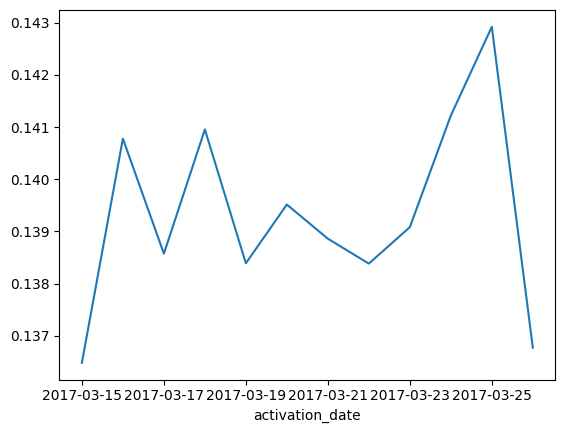

In [ ]:
df_train.groupby(df_train['activation_date'].dt.date)['deal_probability'].mean().plot()

почти все значения 0 (сделка не состоялась)

## Теперь посмотрим признаки и их самые популярные значения

In [9]:
df_train.groupby(['parent_category_name', 'category_name']).count()['user_id']


parent_category_name  category_name               
Бытовая электроника   Аудио и видео                    27036
                      Игры, приставки и программы      11167
                      Настольные компьютеры             5450
                      Ноутбуки                         10297
                      Оргтехника и расходники           6580
                      Планшеты и электронные книги      8624
                      Телефоны                         65944
                      Товары для компьютера            29565
                      Фототехника                       8345
Для бизнеса           Готовый бизнес                    2028
                      Оборудование для бизнеса         16047
Для дома и дачи       Бытовая техника                  33705
                      Мебель и интерьер                65035
                      Посуда и товары для кухни         9076
                      Продукты питания                  5781
                      Растения    

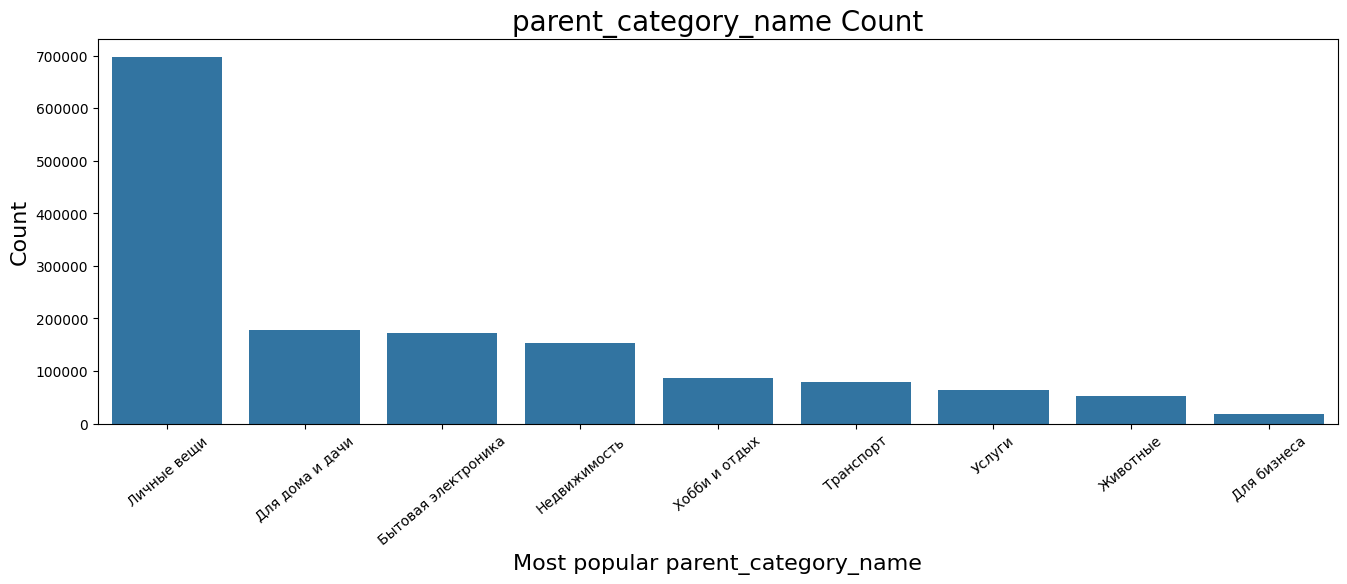

In [10]:
data = df_train['parent_category_name'].value_counts().iloc[:10]
plt.figure(figsize=(16,5))

ax = sns.barplot(x=data.index, y=data.values)
ax.set_xlabel('Most popular parent_category_name', fontsize=16)
ax.set_ylabel('Count', fontsize=16)
ax.set_title('parent_category_name Count', fontsize=20)
plt.xticks(rotation=40);

Тут видно явное превосходство категории `Личные вещи`

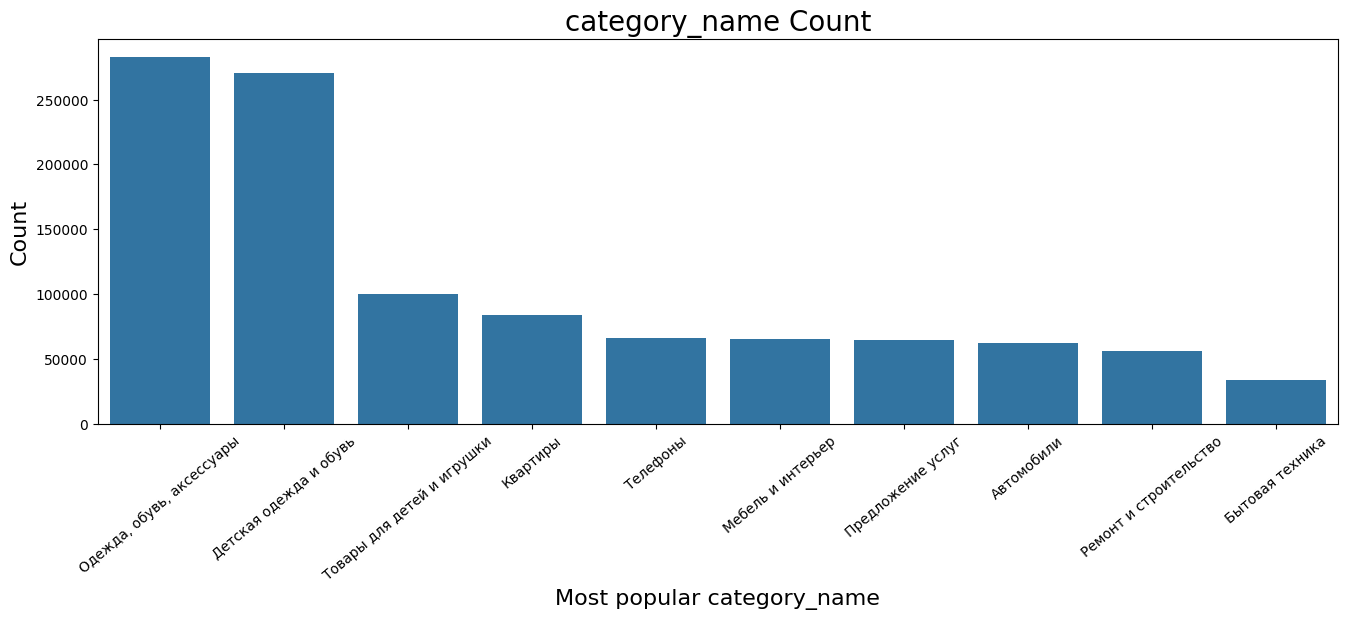

In [11]:
data = df_train['category_name'].value_counts().iloc[:10]
plt.figure(figsize=(16,5))

ax = sns.barplot(x=data.index, y=data.values)
ax.set_xlabel('Most popular category_name', fontsize=16)
ax.set_ylabel('Count', fontsize=16)
ax.set_title('category_name Count', fontsize=20)
plt.xticks(rotation=40);

Оджежду и обувь продают больше всего

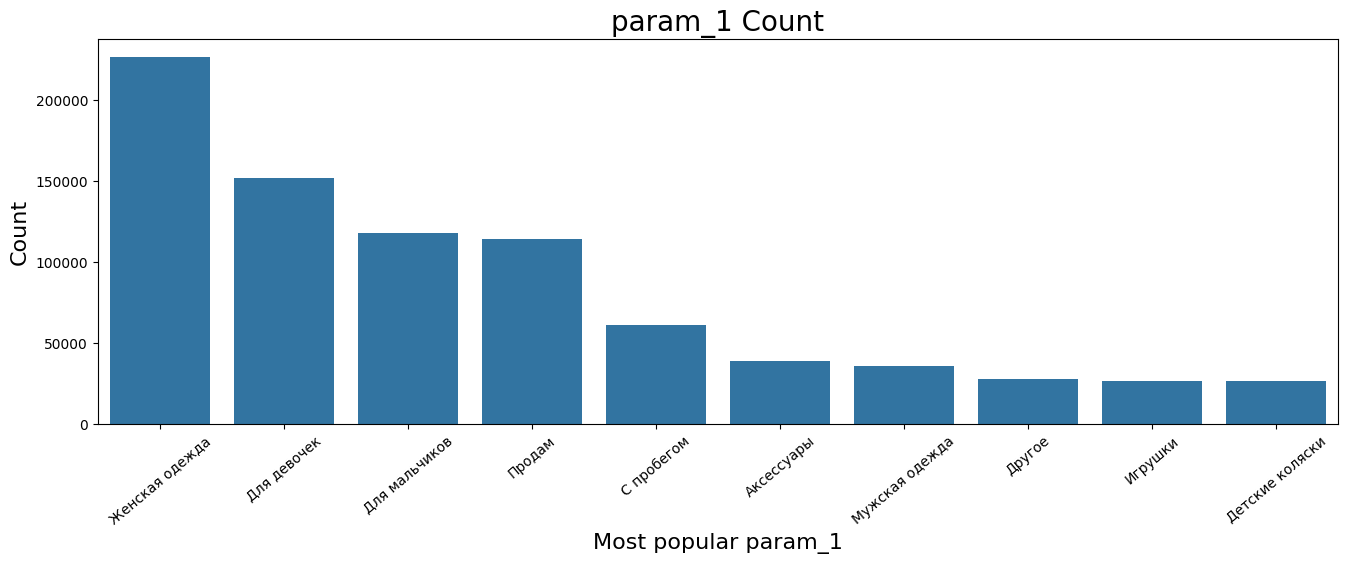

In [12]:
data = df_train['param_1'].value_counts().iloc[:10]
plt.figure(figsize=(16,5))
ax = sns.barplot(x=data.index, y=data.values)
ax.set_xlabel('Most popular param_1', fontsize=16)
ax.set_ylabel('Count', fontsize=16)
ax.set_title('param_1 Count', fontsize=20)
plt.xticks(rotation=40);

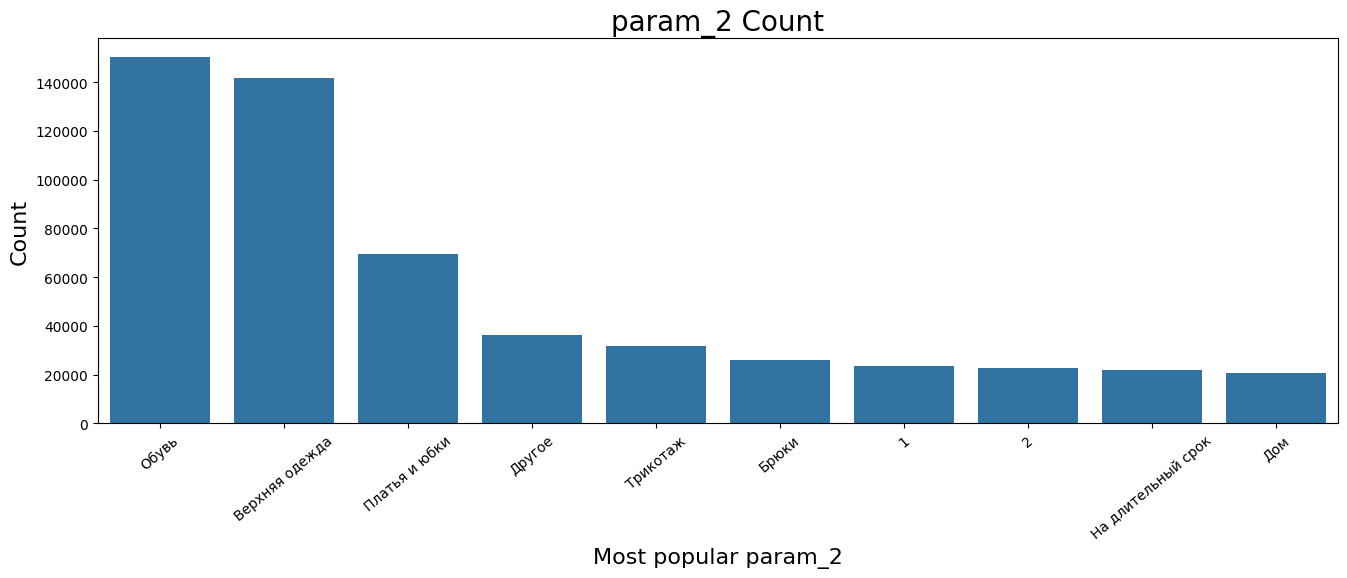

In [13]:
data = df_train['param_2'].value_counts().iloc[:10]
plt.figure(figsize=(16,5))

ax = sns.barplot(x=data.index, y=data.values)
ax.set_xlabel('Most popular param_2', fontsize=16)
ax.set_ylabel('Count', fontsize=16)
ax.set_title('param_2 Count', fontsize=20)
plt.xticks(rotation=40);

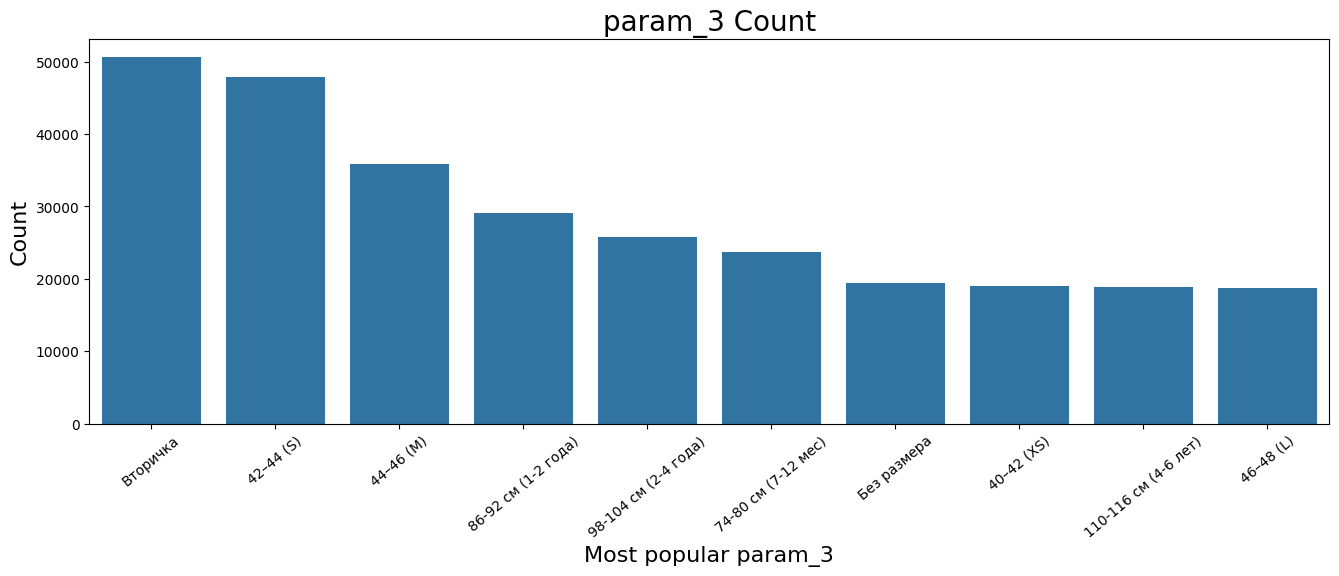

In [14]:
data = df_train['param_3'].value_counts().iloc[:10]
plt.figure(figsize=(16,5))

ax = sns.barplot(x=data.index, y=data.values)
ax.set_xlabel('Most popular param_3', fontsize=16)
ax.set_ylabel('Count', fontsize=16)
ax.set_title('param_3 Count', fontsize=20)
plt.xticks(rotation=40);

Можно заметить, что чаще всего продается одежда для взрослых и детей. Обязательно учтем эти фичи в дальнейшем

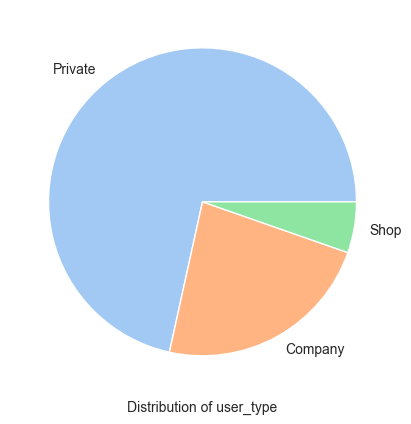

In [31]:
pie_data = df_train['user_type'].value_counts()
sns.set_style("darkgrid")
f, ax = plt.subplots(figsize=(10,5))

colors = sns.color_palette('pastel')
ax.pie(pie_data.values, labels=pie_data.index, colors=colors)
ax.set_xlabel('Distribution of user_type')
plt.show()

Видно, что больше всего публикуют объявления обычные пользователи

<Axes: >

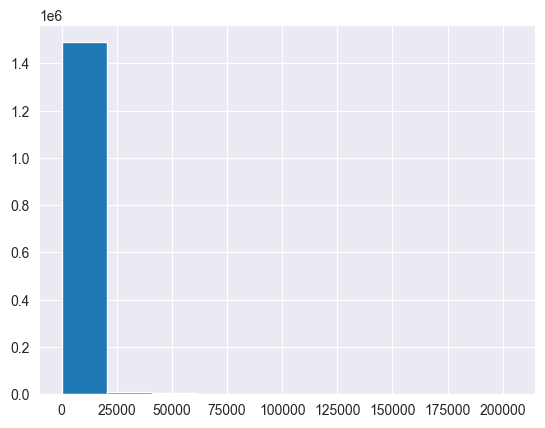

In [16]:
df_train['item_seq_number'].hist()


In [17]:
df_train['item_seq_number'].value_counts()

item_seq_number
1        90378
2        58481
3        48047
4        42074
5        37679
         ...  
59469        1
13879        1
23506        1
71711        1
71005        1
Name: count, Length: 28232, dtype: int64

<Axes: >

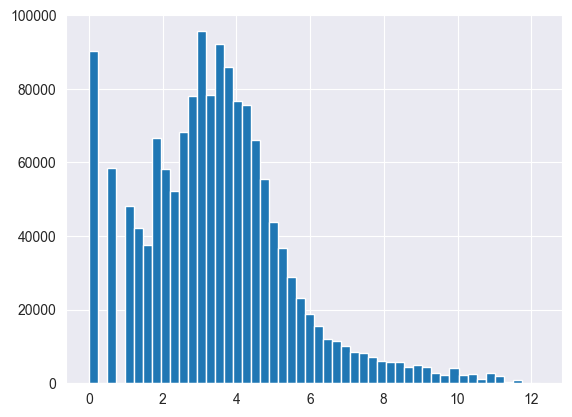

In [18]:
np.log(df_train['item_seq_number']).hist(bins=50)

<Axes: >

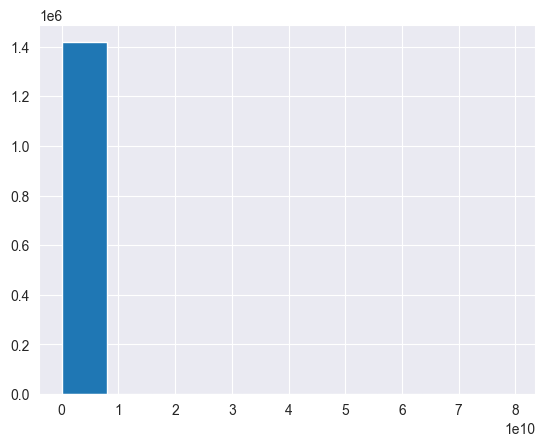

In [19]:
df_train['price'].hist()

<Axes: >

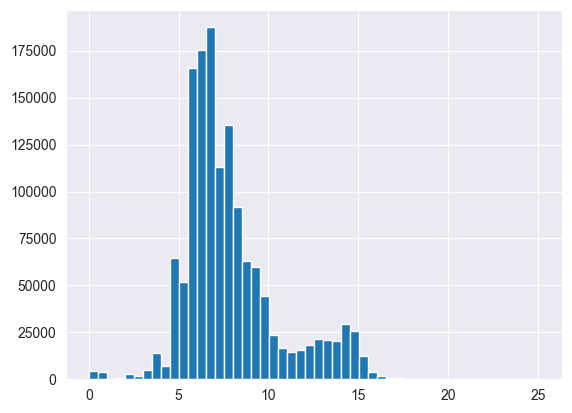

In [20]:
np.log(1 + df_train['price']).hist(bins=50)

### Взаимосвязь признаков

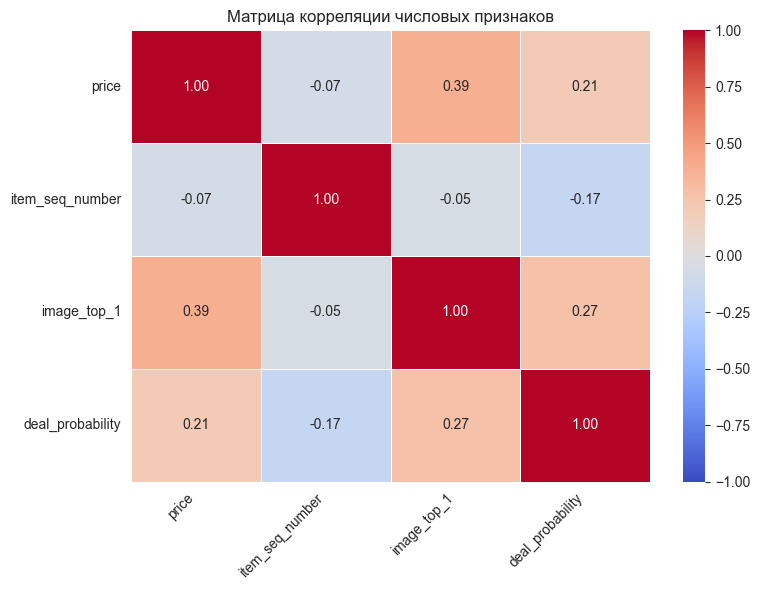

In [30]:
numeric_df = df_train.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    cbar=True
)

plt.title("Матрица корреляции числовых признаков")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Достаточно неинформативно :(

# Выводы

- В данных больше всего категориальных признаков. Также есть один временной, два текстовых, два численных.
- Есть пропуски в параметрах, описании, цене и информации об изображении. Надо не забыть их обработать.
- `title` и `description` потенциально содержат полезную информацию, но надо подумать, как с ними работать
- `activation_date` содержит всего 21 уникальное значение. То есть данные собраны за 21 день. Так что пригодится максимум признак день недели
- `image` - идентификатор изображения, пригодится только если будем джоинить и работать с самим изображением
-  `image_top_1` - классификатор от самого Авито, может быть полезным
- `item_seq_number` показывает, какое по счеу пользователь выкладывает объявление. Может быть полезным.